# Modelagem com K-Means para Clusterizacao do Airbnb NYC

**Dataset de entrada:** `data/processed/master.csv` (48.895 linhas x 12 colunas, ja limpo e sem nulos).

**Objetivo:** aplicar o algoritmo K-Means sobre a base padronizada, determinar o K ideal via metodo Elbow e metricas de validacao (Silhouette, Davies-Bouldin, Calinski-Harabasz), visualizar os clusters com PCA e UMAP, e realizar o perfilamento final dos grupos.

---

### Sumario

| Secao | Topico |
| :--- | :--- |
| [1.0](#1.0) | Configuracao do Ambiente e Carregamento dos Dados |
| [2.0](#2.0) | Preparacao da Base de Perfilamento, Clipping e Padronizacao Robusta |
| [3.0](#3.0) | Modelagem com K-Means — teoria, Elbow, metricas, ajuste final |
| [4.0](#4.0) | Reducao de Dimensionalidade e Visualizacao Topologica (PCA, UMAP) |
| [5.0](#5.0) | Perfilamento dos Clusters (Cluster Profiling) |

___

## 1.0 Configuracao do Ambiente e Carregamento dos Dados

In [1]:
import os
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans, DBSCAN
import hdbscan
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import umap

sys.path.append(os.path.abspath('..'))
%load_ext autoreload
%autoreload 2

from utils_2 import (
    resumo_estatistico_numerico,
    plot_elbow_comparativo,
    plot_metricas_validacao,
    plot_distribuicao_clusters,
    plot_clusters_2d_plotly,
    plot_clusters_3d_matplotlib,
)

warnings.filterwarnings('ignore')

In [2]:
# Carregamento do dataset processado (saida do notebook 01_EDA.ipynb)
nome_arquivo = 'master.csv'
DIR_ATUAL = os.getcwd()
DIR_ARQ = os.path.join(DIR_ATUAL, '..', 'data', 'processed', nome_arquivo)

X = pd.read_csv(DIR_ARQ)

display(X.head(10))
X.info()

,latitude,longitude,room_type,availability_365,price_log,reviews_per_month_log,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,distancia_Times_Square,custo_estadia_log,volume_oferta_dias_anfitriao_log,taxa_reviews_mes_log
0,40.64749,-73.97237,1,365,5.010635,0.190620,1,0,0,0,0.111287,5.010635,7.692113,3.780933
1,40.75362,-73.98377,2,355,5.420535,0.322083,0,1,0,0,0.004709,5.420535,6.566672,4.782653
2,40.80902,-73.94190,1,365,5.017280,0.000000,0,1,0,0,0.067112,6.111467,5.902633,0.000000
3,40.68514,-73.95976,2,194,4.499810,1.729884,1,0,0,0,0.077273,4.499810,5.273000,4.080747
4,40.79851,-73.94399,2,0,4.394449,0.095310,0,1,0,0,0.058001,6.685861,0.000000,4.510850
5,40.74767,-73.97500,2,129,5.303305,0.463734,0,1,0,0,0.014730,6.398595,4.867534,4.839638
6,40.68688,-73.95596,1,0,4.110874,0.336472,1,0,0,0,0.077011,7.901377,0.000000,4.816239
7,40.76489,-73.98493,1,220,4.382027,1.497388,0,1,0,0,0.006914,5.068904,5.398163,4.827668
8,40.80178,-73.96723,1,0,4.382027,0.688135,0,1,0,0,0.047439,5.068904,0.000000,4.789089
9,40.71344,-73.99037,2,188,5.017280,0.845868,0,1,0,0,0.044825,5.017280,6.624065,4.798272


<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   latitude                           48895 non-null  float64
 1   longitude                          48895 non-null  float64
 2   room_type                          48895 non-null  int64  
 3   availability_365                   48895 non-null  int64  
 4   price_log                          48895 non-null  float64
 5   reviews_per_month_log              48895 non-null  float64
 6   neighbourhood_group_Brooklyn       48895 non-null  int64  
 7   neighbourhood_group_Manhattan      48895 non-null  int64  
 8   neighbourhood_group_Queens         48895 non-null  int64  
 9   neighbourhood_group_Staten Island  48895 non-null  int64  
 10  distancia_Times_Square             48895 non-null  float64
 11  custo_estadia_log                  48895 non-null  float64
 12  v

___

## 2.0 Preparacao da Base de Perfilamento, Tratamento de Outliers e Padronizacao 

>
> **X_analise:** as colunas em escala log (`_log`) sao revertidas com `np.expm1` para obter valores na escala original (US$, dias, etc.), permitindo interpretacao direta no perfilamento final.
>
> **X_tratado:** aplica-se clipping (reduzir outliers) nos quantis 0.01 e 0.99 para conter outliers extremos, seguido de `RobustScaler` para normalizar via mediana e IQR, preservando as dummies binarias intactas.

In [3]:
# X_analise: base em escala real para o perfilamento (Secao 5.0)
X_analise = X.copy()

cols_log = [
    'price_log',
    'reviews_per_month_log',
    'custo_estadia_log',
    'volume_oferta_dias_anfitriao_log',
    'taxa_reviews_mes_log',
]

for col in cols_log:
    nome_original = col.replace('_log', '')
    X_analise[nome_original] = np.expm1(X_analise[col])
    X_analise = X_analise.drop(columns=[col])

X_analise.info()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   latitude                           48895 non-null  float64
 1   longitude                          48895 non-null  float64
 2   room_type                          48895 non-null  int64  
 3   availability_365                   48895 non-null  int64  
 4   neighbourhood_group_Brooklyn       48895 non-null  int64  
 5   neighbourhood_group_Manhattan      48895 non-null  int64  
 6   neighbourhood_group_Queens         48895 non-null  int64  
 7   neighbourhood_group_Staten Island  48895 non-null  int64  
 8   distancia_Times_Square             48895 non-null  float64
 9   price                              48895 non-null  float64
 10  reviews_per_month                  48895 non-null  float64
 11  custo_estadia                      48895 non-null  float64
 12  v

In [4]:
# 1. Separar latitude e longitude para uso futuro no GeoPandas 
X_geo = X[['latitude', 'longitude']].copy()
X_modelo = X.drop(columns=['latitude', 'longitude'])

# 2. Clipping nos quantis 0.01 e 0.99 
limite_inferior = X_modelo.quantile(0.01)
limite_superior = X_modelo.quantile(0.99)
X_clipado = X_modelo.clip(lower=limite_inferior, upper=limite_superior, axis=1)

# 3. RobustScaler para a modelagem (
padronizador = RobustScaler().fit(X_clipado)
X_tratado = pd.DataFrame(
    padronizador.transform(X_clipado),
    columns=X_clipado.columns,
    index=X_clipado.index
)

display(X_tratado.head(10))

,room_type,availability_365,price_log,reviews_per_month_log,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,distancia_Times_Square,custo_estadia_log,volume_oferta_dias_anfitriao_log,taxa_reviews_mes_log
0,-1.0,1.409692,0.366389,-0.136688,1.0,0.0,0.0,0.0,0.841965,-0.412629,0.621053,0.379815
1,0.0,1.365639,0.810971,0.008005,0.0,1.0,0.0,0.0,-1.096765,-0.169783,0.426778,0.664264
2,-1.0,1.409692,0.373596,-0.346491,0.0,1.0,0.0,0.0,0.033567,0.239563,0.312150,-1.018622
3,0.0,0.656388,-0.187659,1.557475,1.0,0.0,0.0,0.0,0.219514,-0.715270,0.203461,0.490706
4,0.0,-0.198238,-0.301934,-0.241589,0.0,1.0,0.0,0.0,-0.133155,0.579865,-0.706773,0.649786
5,0.0,0.370044,0.683822,0.163910,0.0,1.0,0.0,0.0,-0.925015,0.409673,0.133469,0.664264
6,-1.0,-0.198238,-0.609503,0.023841,1.0,0.0,0.0,0.0,0.214715,1.300002,-0.706773,0.664264
7,-1.0,0.770925,-0.315408,1.301583,0.0,1.0,0.0,0.0,-1.068046,-0.378108,0.225067,0.664264
8,-1.0,-0.198238,-0.315408,0.410892,0.0,1.0,0.0,0.0,-0.326437,-0.378108,-0.706773,0.664264
9,0.0,0.629956,0.373596,0.584499,0.0,1.0,0.0,0.0,-0.374270,-0.408693,0.436685,0.664264


___

## 3.0 Modelagem com K-Means

### 3.1 Fundamentos Matematicos

K-Means e um algoritmo que separa um conjunto de `n` pontos em `k` grupos/clusters com pontos semelhantes entre si.

Cada grupo (cluster) possui um **centroide**, que e atribuido como o centro de cada cluster. Ele **nao necessariamente e um ponto real do dataset**.

#### Formula do centroide

$$
\mu_k = \frac{1}{|C_k|} \sum_{x_i \in C_k} x_i
$$

Onde:
- `C_k` = conjunto de pontos atribuidos ao cluster `k`
- `|C_k|` = numero de pontos no cluster `k`
- `x_i` = vetor de features do ponto `i`

#### Distancia Euclidiana

$$
d(x, \mu) = \sqrt{\sum_{j=1}^{d} (x_j - \mu_j)^2}
$$

Na pratica, o K-Means usa a **distancia euclidiana ao quadrado** (sem a raiz), pois e mais barato computacionalmente e leva ao mesmo resultado de atribuicao:

$$
\|x - \mu\|^2 = \sum_{j=1}^{d} (x_j - \mu_j)^2
$$

> Por isso, e extremamente importante **padronizar os dados de entrada**. Features com escalas diferentes dominariam o calculo da distancia.

### 3.2 Ciclo do Algoritmo

O algoritmo e iterativo e alterna entre atribuicao e recalculo dos centros:

**1) Inicializar centros aleatorios (Forgy / K-Means++)**

O metodo de Forgy sorteia `k` pontos reais do dataset como centros iniciais. Uma alternativa melhor e o **K-Means++**, que escolhe centros espalhados proporcionalmente a **distancia ao quadrado ao centro mais proximo** ja escolhido.

**2) Atribuir cada ponto ao centroide mais proximo**

$$
\text{cluster}(x_i) = \arg\min_{k=1,\dots,K} \|x_i - \mu_k\|^2
$$

**3) Recalcular os centroides**

$$
\mu_k \leftarrow \frac{1}{|C_k|} \sum_{x_i \in C_k} x_i
$$

**4) Repetir ate convergir**

Repete-se os passos 2 e 3 ate que as atribuicoes nao mudem mais, os centroides se movam menos que uma tolerancia `epsilon`, ou atinja-se um numero maximo de iteracoes.

> Cada passo nunca aumenta a inercia, entao o algoritmo converge — mas para um **minimo local**. Por isso e comum rodar varias inicializacoes (`n_init`) e ficar com a de menor inercia.

### 3.3 Metricas de Avaliacao

Como nao ha rotulos verdadeiros, avaliamos a qualidade geometrica da particao: **coesao** (pontos perto do seu centroide) e **separacao** (clusters longe uns dos outros).

#### Inertia (WCSS — Within-Cluster Sum of Squares)

$$
\text{Inertia} = \sum_{k=1}^{K} \sum_{x_i \in C_k} \|x_i - \mu_k\|^2
$$

- **Menor e melhor** (e o objetivo que o K-Means minimiza).
- **Nao serve para comparar `k` diferentes**, pois sempre diminui quando `k` aumenta.
- Uso classico: **metodo do cotovelo (elbow)** — plotar inercia vs. `k` e procurar o "joelho" da curva.

#### Silhouette (Coeficiente de Silhueta)

Para cada ponto `i`:
- `a(i)` = distancia media aos outros pontos do **mesmo cluster** (coesao)
- `b(i)` = distancia media aos pontos do **cluster vizinho mais proximo** (separacao)

$$
s(i) = \frac{b(i) - a(i)}{\max(a(i),\, b(i))} \in [-1, 1]
$$

- **Maior e melhor** (perto de +1 = ponto bem dentro do seu cluster).
- Custo `O(n^2)` (distancias par a par) — caro para `n` grande.

#### Davies-Bouldin

$$
\text{DB} = \frac{1}{K} \sum_{i=1}^{K} \max_{j \neq i} \frac{s_i + s_j}{d(\mu_i,\, \mu_j)}
$$

- Mede a razao **dispersao interna / separacao entre clusters**.
- **Menor e melhor** (0 e o ideal).

#### Calinski-Harabasz (Variance Ratio Criterion)

$$
\text{CH} = \frac{\operatorname{tr}(B_K)/(K-1)}{\operatorname{tr}(W_K)/(n-K)}
$$

- **Maior e melhor** (clusters compactos e bem separados).
- Custo `O(n)`, relativamente barato.

| Metrica | O que mede | Direcao | Compara `k`? | Custo |
|---|---|---|---|---|
| **Inertia** | coesao interna (SSE) | menor melhor | nao | `O(nKd)` |
| **Silhouette** | coesao + separacao | maior melhor | sim | `O(n^2)` |
| **Davies-Bouldin** | dispersao / separacao | menor melhor | sim | `O(nKd + K^2d)` |
| **Calinski-Harabasz** | var. entre / var. interna | maior melhor | sim | `O(nKd)` |

### 3.4 Determinacao do K Ideal (Metodo Elbow e Metricas)

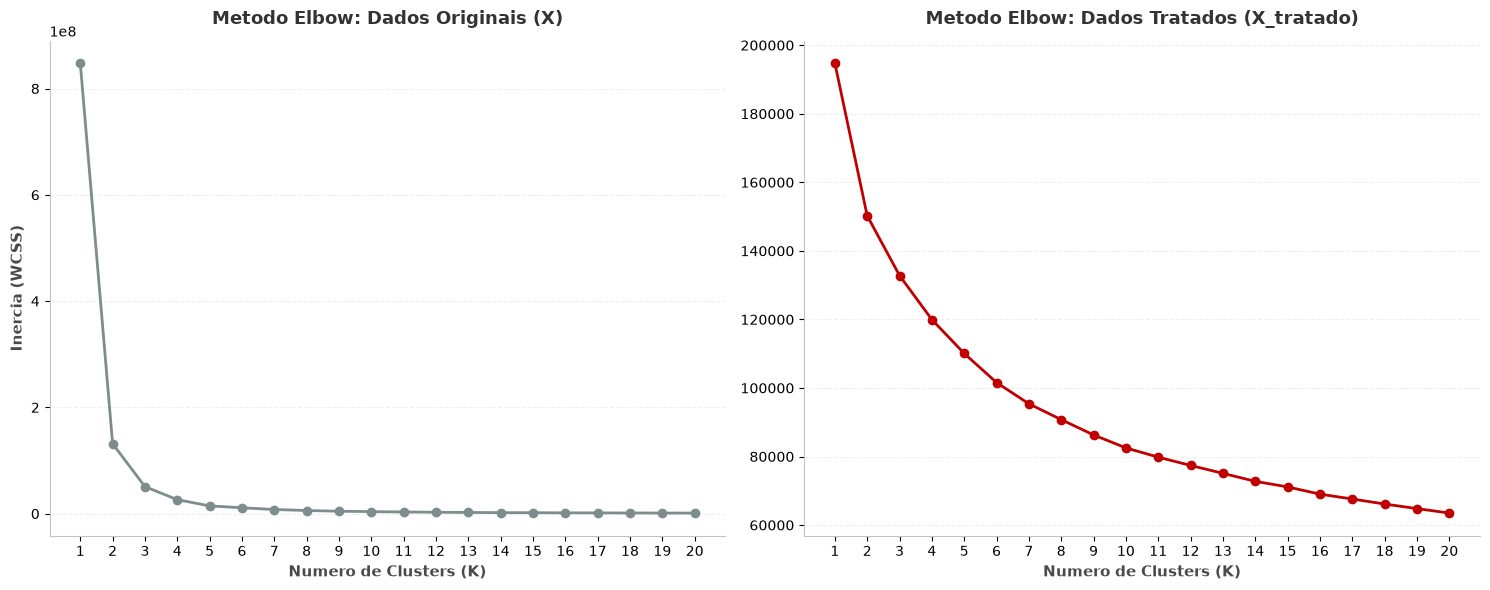

In [5]:
# Metodo Elbow: K=1 ate 20 para X (original) e X_tratado (escalonado)
k_valores = list(range(1, 21))
inercias_x = []
inercias_x_tratado = []

for k in k_valores:
    modelo_km = KMeans(n_clusters=k, init='k-means++', n_init=20,
                       max_iter=300, random_state=10)

    modelo_km.fit(X)
    inercias_x.append(modelo_km.inertia_)

    modelo_km.fit(X_tratado)
    inercias_x_tratado.append(modelo_km.inertia_)

plot_elbow_comparativo(k_valores, inercias_x, inercias_x_tratado)

,K,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz,Tamanho_dos_Clusters
0,2,150237.76,0.20,1.77,14488.99,"{0: 22908, 1: 25987}"
1,3,132805.62,0.17,1.88,11404.04,"{0: 17341, 1: 17575, 2: 13979}"
2,4,119945.53,0.16,1.82,10164.95,"{0: 9558, 1: 13803, 2: 12164, 3: 13370}"
3,5,110072.07,0.17,1.71,9403.74,"{0: 9230, 1: 13221, 2: 9782, 3: 6757, 4: 9905}"
4,6,101585.18,0.18,1.65,8968.21,"{0: 9064, 1: 11135, 2: 3490, 3: 9155, 4: 9317,..."
5,7,95384.26,0.18,1.62,8488.90,"{0: 8996, 1: 9023, 2: 7410, 3: 5620, 4: 5875, ..."
6,8,90762.81,0.18,1.57,8002.13,"{0: 5371, 1: 4726, 2: 3091, 3: 8732, 4: 7493, ..."
7,9,86300.47,0.18,1.60,7679.74,"{0: 2911, 1: 5188, 2: 4767, 3: 4701, 4: 6222, ..."
8,10,82516.50,0.18,1.57,7388.41,"{0: 3921, 1: 6586, 2: 6453, 3: 4389, 4: 4329, ..."


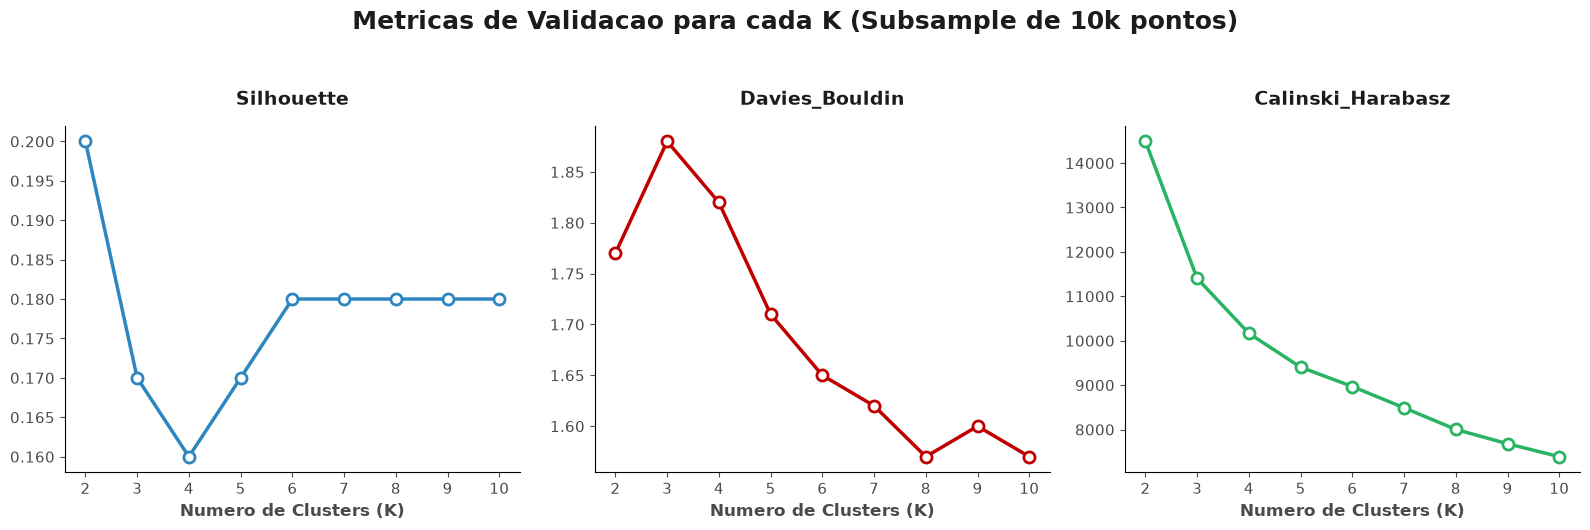

In [6]:
# Metricas de validacao: K=2 ate 10 com subsample de 10k pontos
k_valores = range(2, 11)
resultados_metricas = []

for k in k_valores:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10,
                max_iter=300, random_state=10)
    labels = km.fit_predict(X_tratado)

    valores_unicos, contagens = np.unique(labels, return_counts=True)
    distribuicao_tamanhos = {int(c): int(q) for c, q in zip(valores_unicos, contagens)}

    resultados_metricas.append({
        'K': k,
        'Inertia': km.inertia_,
        'Silhouette': silhouette_score(X_tratado, labels, sample_size=10000, random_state=10), #subsample 10k
        'Davies_Bouldin': davies_bouldin_score(X_tratado, labels),
        'Calinski_Harabasz': calinski_harabasz_score(X_tratado, labels),
        'Tamanho_dos_Clusters': distribuicao_tamanhos,
    })

df_resultados = pd.DataFrame(resultados_metricas)
colunas_float = ['Inertia', 'Silhouette', 'Davies_Bouldin', 'Calinski_Harabasz']
df_resultados[colunas_float] = df_resultados[colunas_float].round(2)
display(df_resultados)

plot_metricas_validacao(df_resultados)

### 3.5 Ajuste do Modelo Final e Distribuicao de Volume

>
> Com base no Elbow (K=8 como ponto de inflexao) e nas metricas de validacao
>
> selecionamos **K=8** como o numero ideal de clusters.

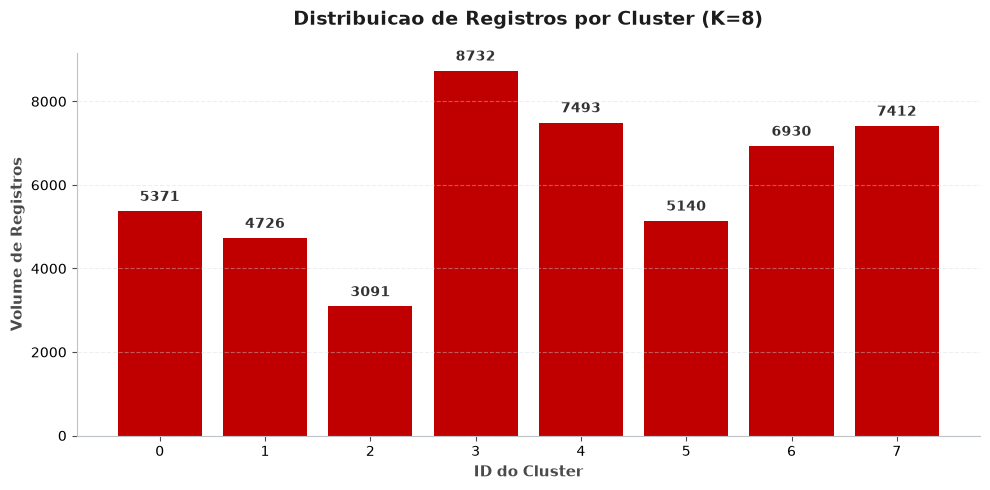

In [7]:
# Ajuste do modelo final com K=4 (K-Means++)
km_final = KMeans(n_clusters=8, init='k-means++', n_init=10,
                  max_iter=300, random_state=10)
labels_k8 = km_final.fit_predict(X_tratado)

# Distribuicao de volume por cluster
plot_distribuicao_clusters(
    labels_k8,
    titulo='Distribuicao de Registros por Cluster (K=8)'
)

___

## 4.0 Reducao de Dimensionalidade e Visualizacao Topologica

In [8]:
# Constantes e paleta de cores corporativa
CORES_CLUSTERS = {
    0: '#7F8C8D',  # Cinza (Baseline / Majoritário)
    1: '#C00000',  # Vermelho
    2: '#007006',  # Verde Escuro
    3: '#A6FF00',  # Verde Neon
    4: '#2E86C1',  # Azul Corporativo
    5: '#F39C12',  # Laranja/Mostarda
    6: '#8E44AD',  # Roxo
    7: '#34495E'   # Azul Escuro/Marinho
}

# PCA: 3 componentes para projecao 2D e 3D
pca = PCA(n_components=3, random_state=10)
X_pca = pca.fit_transform(X_tratado)

var_explicada = pca.explained_variance_ratio_
print(f'Variancia explicada individual: {np.round(var_explicada * 100, 2)}%')
print(f'Variancia total mantida (3 comp.): {var_explicada.sum() * 100:.2f}%')

df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2', 'PC3'])
df_pca['Cluster'] = labels_k8

# UMAP: 2 componentes para projecao topologica nao-linear
redutor_umap = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=10)
X_umap = redutor_umap.fit_transform(X_tratado)

df_umap = pd.DataFrame(X_umap, columns=['UMAP1', 'UMAP2'])
df_umap['Cluster'] = labels_k8

Variancia explicada individual: [33.89 17.44 13.25]%
Variancia total mantida (3 comp.): 64.59%


In [9]:
# Projecao 2D via UMAP (estrutura topologica nao-linear)
plot_clusters_2d_plotly(
    df_umap, col_x='UMAP1', col_y='UMAP2',
    mapa_cores=CORES_CLUSTERS,
    titulo='Projecao 2D (UMAP): Estrutura Topologica dos Clusters'
)

In [10]:
# Projecao 2D via PCA (componentes principais lineares)
plot_clusters_2d_plotly(
    df_pca, col_x='PC1', col_y='PC2',
    mapa_cores=CORES_CLUSTERS,
    titulo='Projecao 2D (PCA): Componentes Principais dos Clusters'
)

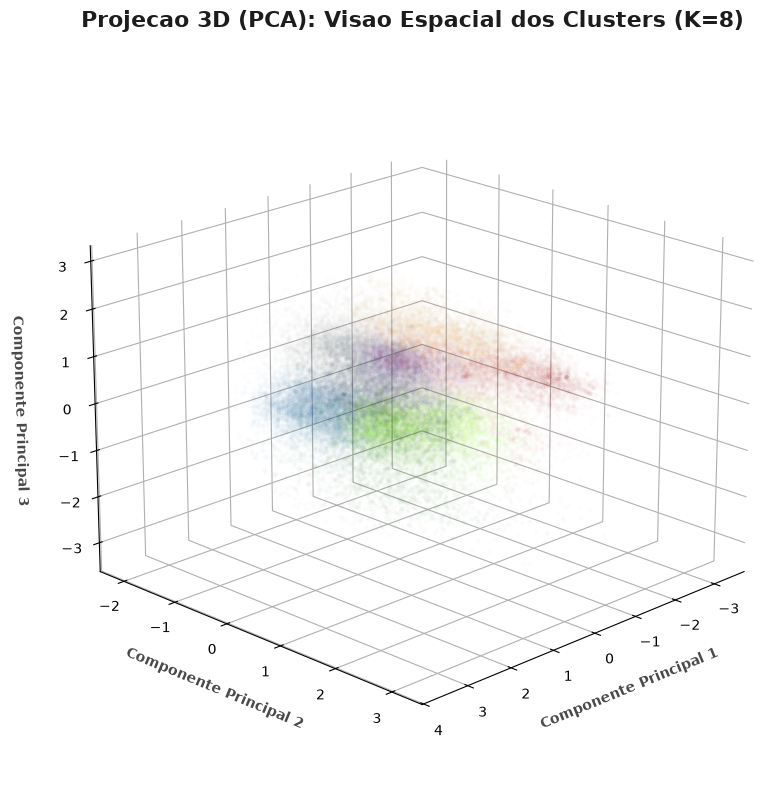

In [11]:
# Projecao 3D via PCA (visao espacial tridimensional)
plot_clusters_3d_matplotlib(
    df_pca,
    cols_xyz=('PC1', 'PC2', 'PC3'),
    labels=labels_k8,
    mapa_cores=CORES_CLUSTERS,
    titulo='Projecao 3D (PCA): Visao Espacial dos Clusters (K=8)',
    labels_eixos=('Componente Principal 1', 'Componente Principal 2', 'Componente Principal 3'),
    alpha=0.15,
    s=10,
    elev=20,
    azim=45
)

___

## 5.0 Perfilamento dos Clusters (Cluster Profiling)

In [12]:
# Atribuicao dos labels de cluster a base em escala real
X_analise['Cluster_KMeans'] = labels_k8

# Perfil quantitativo: mediana das variaveis continuas, moda de room_type e contagem
perfil_quantitativo = X_analise.groupby('Cluster_KMeans').agg(
    Preco_Mediano=('price', 'median'),
    Custo_Estadia_Mediano=('custo_estadia', 'median'),
    Distancia_Times_Square_Mediana=('distancia_Times_Square', 'median'),
    Reviews_Mes_Mediano=('reviews_per_month', 'median'),
    Taxa_Reviews_Mediana=('taxa_reviews_mes', 'median'),
    Disponibilidade_Mediana=('availability_365', 'median'),
    Volume_Oferta_Host=('volume_oferta_dias_anfitriao', 'median'),
    room_type_Moda=('room_type', lambda x: x.mode().iloc[0] if not x.mode().empty else None),
    Tamanho_do_Cluster=('price', 'count'),
).round(2)

display(perfil_quantitativo)

,Preco_Mediano,Custo_Estadia_Mediano,Distancia_Times_Square_Mediana,Reviews_Mes_Mediano,Taxa_Reviews_Mediana,Disponibilidade_Mediana,Volume_Oferta_Host,room_type_Moda,Tamanho_do_Cluster
Cluster_KMeans,,,,,,,,,
0,80.0,165.0,0.05,0.15,16.67,0.0,0.0,1,5371
1,222.0,4210.5,0.03,0.08,2.27,311.0,1013.0,2,4726
2,75.0,135.0,0.18,1.26,10.75,170.0,283.0,1,3091
3,150.0,500.0,0.08,0.39,21.64,20.0,22.0,2,8732
4,60.0,149.0,0.08,0.09,12.04,0.0,0.0,1,7493
5,150.0,300.0,0.04,2.59,15.70,189.0,247.0,2,5140
6,185.0,596.0,0.03,0.13,18.42,0.0,0.0,2,6930
7,65.0,130.0,0.09,1.58,15.98,249.0,360.0,1,7412


In [13]:
# Distribuicao percentual dos distritos (neighbourhood_group) por cluster
bairros_dummies = [
    'neighbourhood_group_Brooklyn',
    'neighbourhood_group_Manhattan',
    'neighbourhood_group_Queens',
    'neighbourhood_group_Staten Island',
]

distribuicao_distritos = (
    X_analise.groupby('Cluster_KMeans')[bairros_dummies]
    .mean()
    .mul(100)
    .round(1)
)
display(distribuicao_distritos)

,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island
Cluster_KMeans,,,,
0,0.0,98.6,1.4,0.0
1,8.6,88.6,2.4,0.1
2,7.8,0.1,64.3,11.4
3,92.4,0.5,6.0,0.1
4,83.6,0.1,14.1,0.1
5,1.6,93.0,5.2,0.0
6,0.0,97.7,2.3,0.0
7,68.0,7.8,20.0,0.0


# Analisando por HDB

In [14]:
# Grade de Hiperparâmetros
grade_eps = [0.3, 0.5, 0.8, 1.0, 1.2]
grade_min_samples = [15, 30, 50, 100]

# total = 16 combinações

resultados_dbscan = []

print("Iniciando varredura de hiperparâmetros do DBSCAN...\n")

# Testando todos os parâmetros ( semelhante ao grid search )
for eps in grade_eps:
    for min_samples in grade_min_samples:
        
        # Treinamento do modelo
        modelo_db = DBSCAN(eps=eps, min_samples=min_samples)
        labels = modelo_db.fit_predict(X_tratado)
        
        # Conta o número de clusters encontrados (Ignorando o rótulo -1, que é ruído)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        
        # Calcula o percentual de dados classificados como ruído
        qtd_ruido = list(labels).count(-1)
        perc_ruido = (qtd_ruido / len(labels)) * 100
        
        # Trava: Roda apenas com 2 cluster validos
        if n_clusters > 1:
            # Dica: Calculamos as métricas com sample_size para não travar a memória
            sil = silhouette_score(X_tratado, labels, sample_size=10000, random_state=42)
            db = davies_bouldin_score(X_tratado, labels)
            ch = calinski_harabasz_score(X_tratado, labels)
        else:
            # Se encontrou apenas 1 cluster ou só ruído, anulamos as métricas
            sil, db, ch = np.nan, np.nan, np.nan
            
        resultados_dbscan.append({
            'eps': eps,
            'min_samples': min_samples,
            'N_Clusters': n_clusters,
            '%_Ruido': round(perc_ruido, 2),
            'Silhouette': sil,
            'Davies_Bouldin': db,
            'Calinski_Harabasz': ch
        })
        
        print(f"Testado: eps={eps} | min_samples={min_samples} -> Clusters: {n_clusters} | Ruído: {perc_ruido:.1f}%")

df_dbscan = pd.DataFrame(resultados_dbscan)

display(df_dbscan.sort_values(by='Davies_Bouldin').head(10))

Iniciando varredura de hiperparâmetros do DBSCAN...

Testado: eps=0.3 | min_samples=15 -> Clusters: 48 | Ruído: 72.0%
Testado: eps=0.3 | min_samples=30 -> Clusters: 22 | Ruído: 78.4%
Testado: eps=0.3 | min_samples=50 -> Clusters: 15 | Ruído: 84.3%
Testado: eps=0.3 | min_samples=100 -> Clusters: 10 | Ruído: 94.0%
Testado: eps=0.5 | min_samples=15 -> Clusters: 50 | Ruído: 25.7%
Testado: eps=0.5 | min_samples=30 -> Clusters: 21 | Ruído: 39.7%
Testado: eps=0.5 | min_samples=50 -> Clusters: 21 | Ruído: 51.3%
Testado: eps=0.5 | min_samples=100 -> Clusters: 12 | Ruído: 65.1%
Testado: eps=0.8 | min_samples=15 -> Clusters: 23 | Ruído: 3.2%
Testado: eps=0.8 | min_samples=30 -> Clusters: 16 | Ruído: 6.5%
Testado: eps=0.8 | min_samples=50 -> Clusters: 9 | Ruído: 10.2%
Testado: eps=0.8 | min_samples=100 -> Clusters: 6 | Ruído: 17.6%
Testado: eps=1.0 | min_samples=15 -> Clusters: 10 | Ruído: 1.0%
Testado: eps=1.0 | min_samples=30 -> Clusters: 10 | Ruído: 2.0%
Testado: eps=1.0 | min_samples=50 -> Clu

,eps,min_samples,N_Clusters,%_Ruido,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,0.3,15,48,71.96,-0.264861,1.231260,321.602391
3,0.3,100,10,94.04,-0.322132,1.238704,302.241532
2,0.3,50,15,84.28,-0.256949,1.297521,506.811729
1,0.3,30,22,78.41,-0.229185,1.299569,508.794971
4,0.5,15,50,25.67,-0.096467,1.427520,676.211147
6,0.5,50,21,51.31,-0.088969,1.491949,1153.703761
7,0.5,100,12,65.12,-0.097408,1.497490,1471.217567
5,0.5,30,21,39.74,-0.033533,1.518216,1377.095221
8,0.8,15,23,3.24,0.014283,1.877748,1508.976562
9,0.8,30,16,6.46,0.035999,1.934074,2082.901291


In [15]:
# 1. Grade de Hiperparâmetros focada em densidade (Adaptada para 48k linhas)
grade_min_cluster_size = [50, 100, 200, 500]
grade_min_samples = [15, 30, 50]

resultados_hdbscan = []

print("Iniciando varredura de hiperparâmetros do HDBSCAN...\n")

# 2. Testando as combinações
for min_cluster_size in grade_min_cluster_size:
    for min_samples in grade_min_samples:
        
        # Treinamento do modelo HDBSCAN
        # core_dist_n_jobs=-1 utiliza todos os núcleos do processador para acelerar
        modelo_hdb = hdbscan.HDBSCAN(
            min_cluster_size=min_cluster_size,
            min_samples=min_samples,
            core_dist_n_jobs=-1 
        )
        
        labels = modelo_hdb.fit_predict(X_tratado)
        
        # Conta o número de clusters encontrados (Ignorando o rótulo -1, que é ruído)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        
        # Calcula o percentual de dados classificados como ruído (-1)
        qtd_ruido = list(labels).count(-1)
        perc_ruido = (qtd_ruido / len(labels)) * 100
        
        # 3. Trava de segurança: Roda métricas apenas com 2 ou mais clusters válidos
        if n_clusters > 1:
            # Subsample de 10k para o Silhouette para evitar estouro de RAM
            sil = silhouette_score(X_tratado, labels, sample_size=10000, random_state=42)
            db = davies_bouldin_score(X_tratado, labels)
            ch = calinski_harabasz_score(X_tratado, labels)
        else:
            sil, db, ch = np.nan, np.nan, np.nan
            
        resultados_hdbscan.append({
            'min_cluster_size': min_cluster_size,
            'min_samples': min_samples,
            'N_Clusters': n_clusters,
            '%_Ruido': round(perc_ruido, 2),
            'Silhouette': sil,
            'Davies_Bouldin': db,
            'Calinski_Harabasz': ch
        })
        
        print(f"Testado: min_cluster_size={min_cluster_size:3} | min_samples={min_samples:2} -> Clusters: {n_clusters:2} | Ruído: {perc_ruido:.1f}%")

# 4. Compilação e visualização dos resultados
df_hdbscan = pd.DataFrame(resultados_hdbscan)

# Exibe ordenando pelo melhor Davies-Bouldin (menor é melhor)
display(df_hdbscan.sort_values(by='Davies_Bouldin').head(10))

Iniciando varredura de hiperparâmetros do HDBSCAN...

Testado: min_cluster_size= 50 | min_samples=15 -> Clusters: 17 | Ruído: 18.8%
Testado: min_cluster_size= 50 | min_samples=30 -> Clusters: 15 | Ruído: 17.4%
Testado: min_cluster_size= 50 | min_samples=50 -> Clusters: 13 | Ruído: 21.0%
Testado: min_cluster_size=100 | min_samples=15 -> Clusters: 17 | Ruído: 18.8%
Testado: min_cluster_size=100 | min_samples=30 -> Clusters: 15 | Ruído: 17.4%
Testado: min_cluster_size=100 | min_samples=50 -> Clusters: 11 | Ruído: 21.3%
Testado: min_cluster_size=200 | min_samples=15 -> Clusters: 12 | Ruído: 8.4%
Testado: min_cluster_size=200 | min_samples=30 -> Clusters:  7 | Ruído: 7.8%
Testado: min_cluster_size=200 | min_samples=50 -> Clusters:  7 | Ruído: 11.3%
Testado: min_cluster_size=500 | min_samples=15 -> Clusters:  9 | Ruído: 12.5%
Testado: min_cluster_size=500 | min_samples=30 -> Clusters:  7 | Ruído: 7.8%
Testado: min_cluster_size=500 | min_samples=50 -> Clusters:  6 | Ruído: 11.9%


,min_cluster_size,min_samples,N_Clusters,%_Ruido,Silhouette,Davies_Bouldin,Calinski_Harabasz
2,50,50,13,21.02,0.011187,2.012352,2249.486838
0,50,15,17,18.76,-0.017612,2.016761,2205.010064
3,100,15,17,18.76,-0.017612,2.016761,2205.010064
1,50,30,15,17.44,0.005685,2.018216,2187.709136
4,100,30,15,17.44,0.005685,2.018216,2187.709136
5,100,50,11,21.29,0.027072,2.086888,2618.951534
6,200,15,12,8.45,0.063875,2.280689,2923.254803
9,500,15,9,12.47,0.084701,2.438076,3644.810968
8,200,50,7,11.33,0.110430,2.614442,4166.058890
11,500,50,6,11.88,0.136313,2.639801,4805.710920


In [ ]:
# 1. Ajuste do modelo final com os melhores hiperparâmetros
hdb_final = hdbscan.HDBSCAN(
    min_cluster_size=50, 
    min_samples=50, 
    core_dist_n_jobs=-1
)

labels_hdb = hdb_final.fit_predict(X_tratado)

# 2. Criar uma nova coluna de Cluster no DataFrame do UMAP
df_umap['Cluster_HDBSCAN'] = labels_hdb

# 3. Preparar a paleta de cores (Ruído recebe cor cinza claro)

cores_plotly = px.colors.qualitative.Alphabet 
mapa_cores_hdb = {str(i): cores_plotly[i % len(cores_plotly)] for i in range(13)}
mapa_cores_hdb['-1'] = '#E5E7E9' # Ruído em cinza claro e apagado

# 4. Projeção 2D via UMAP
plot_clusters_2d_plotly(
    df_umap, 
    col_x='UMAP1', 
    col_y='UMAP2', 
    col_cluster='Cluster_HDBSCAN',
    mapa_cores=mapa_cores_hdb,
    titulo='Projeção 2D (UMAP): Clusters Geométricos vs Ruído (HDBSCAN)'
)